# Whole scene: table, objects and background in one splat

The ChArUco scan of `table_zoom_02` + `table_zoom_03` (one SfM model, 120/120 keyframes registered, metric table frame, z up, tabletop at z = 0) was cut into tabletop, background, plate and bowl for the sim. Here the pieces go back together into **one splat of the whole room view**, and the scene is viewed two ways: Gaussian centres in 3D, and full Gaussian renders from the phone's own camera path next to the photos.

- **Modules:** `hurobo.scan` (`merge_plys`, `align_charuco_table`, `SfmResult.t_cam_world_in`), `hurobo.splat.render_scan_path`, `hurobo.utils.viewer` (`splat_figure`, `orbit_figure`)
- **Data:** real phone clips, not committed. Needs `data/splats/table_zoom_02_03_{table,background,plate,bowl}.ply` and `data/scans/table_zoom_02_03/` from `scripts/09_scan_object.py --charuco` (see notebook 06, part 4). Writes `data/splats/table_zoom_02_03_scene.ply`.
- **Limits:** the splat is only good where the phone looked. Seen from the capture cameras it reads as the photos; from far outside the capture path (behind walls, under the table) it is smeared Gaussians. Held-out PSNR of this scan is 25.6 dB (notebook 06).

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()

## 1. Merge the layers into one splat

In [2]:
from hurobo.scan import merge_plys

SPLATS = ROOT / "data/splats"
LAYERS = ["table", "background", "plate", "bowl"]
SCENE = SPLATS / "table_zoom_02_03_scene.ply"
count = merge_plys([SPLATS / f"table_zoom_02_03_{name}.ply" for name in LAYERS], SCENE)
print(f"{count:,} Gaussians -> {SCENE.relative_to(ROOT)}")

776,569 Gaussians -> data/splats/table_zoom_02_03_scene.ply


The layers partition the training splat (nothing was dropped when cutting), so the merged count equals the 776,569 Gaussians the scan trained. Pick *whole scene* or any single layer in the dropdown; orbit with the mouse.

In [3]:
from hurobo.utils.viewer import splat_figure

splat_figure(
    {"whole scene": SCENE} | {name: SPLATS / f"table_zoom_02_03_{name}.ply" for name in LAYERS},
    max_points=20_000,
    title="table_zoom_02_03: whole scene (Gaussian centres, metres, z up)",
).show()

## 2. The scene from the phone's own path
The slider steps through keyframes spread over both clips; each frame is `photo | splat render` from the same camera pose, with the splat in the table frame (cameras are carried along by the ChArUco alignment).

In [4]:
import numpy as np

from hurobo.camera import ChArUcoCalibrator
from hurobo.scan import align_charuco_table, largest_model, load_sparse_models, sfm_result_from_model
from hurobo.splat import render_scan_path
from hurobo.utils.viewer import orbit_figure

WORK = ROOT / "data/scans/table_zoom_02_03"
sfm = sfm_result_from_model(largest_model(load_sparse_models(WORK / "colmap/sparse")), WORK / "images")
board = ChArUcoCalibrator(square_length_m=0.025, marker_length_m=0.0186).board
similarity, rms_m = align_charuco_table(sfm, board, board_thickness_m=0.008)
print(f"scale {similarity.scale:.4f} m/unit, ChArUco corner RMS {1000 * rms_m:.1f} mm")

ids, photos, renders = render_scan_path(SCENE, sfm, similarity, num_views=10)
orbit_figure(
    [np.hstack(pair) for pair in zip(photos, renders, strict=True)],
    title="photo | whole-scene splat, from the capture cameras",
    height=620,
    labels=[f"keyframe {i}" for i in ids],
).show()

scale 0.1441 m/unit, ChArUco corner RMS 0.5 mm


## 3. Rotate, crop and filter the full splat in the browser
The plotly view above shows centres only. This writes a WebGL page that draws the actual Gaussians (colour, size, orientation, opacity). Orbit, pan and zoom with the mouse; the panel on the left has

- x / y / z min and max sliders for a **3D crop box**, drawn as a wireframe; **Apply** reloads the splat with only what is inside (or, with the checkbox, only what is outside);
- a **min opacity** slider to drop floaters;
- **Download .ply** for the filtered splat, and the box printed as `CropBox(x_min, x_max, y_min, y_max, z_min, z_max)` so the same crop can be applied in code with `hurobo.scan.crop_ply`.

Browsers block `file://` fetches, so serve the folder and open the URL (needs internet for the three.js and viewer scripts from jsDelivr, and a GPU browser).

In [5]:
from hurobo.utils.viewer import write_splat_viewer

page = write_splat_viewer(
    SCENE, ROOT / "data/viewer/table_zoom_02_03_scene", title="table_zoom_02_03 whole scene"
)
print(f"uv run python -m http.server 8791 -d {page.parent.relative_to(ROOT)}  ->  http://localhost:8791/")

uv run python -m http.server 8791 -d data/viewer/table_zoom_02_03_scene  ->  http://localhost:8791/


## 4. The scene as a still 3D view
The full Gaussians, cut to the box around the table and rendered from the browser viewer's side of the room (z up, tabletop at z = 0). Still images, so they can go into slides.

494,781 of 776,569 Gaussians inside the box


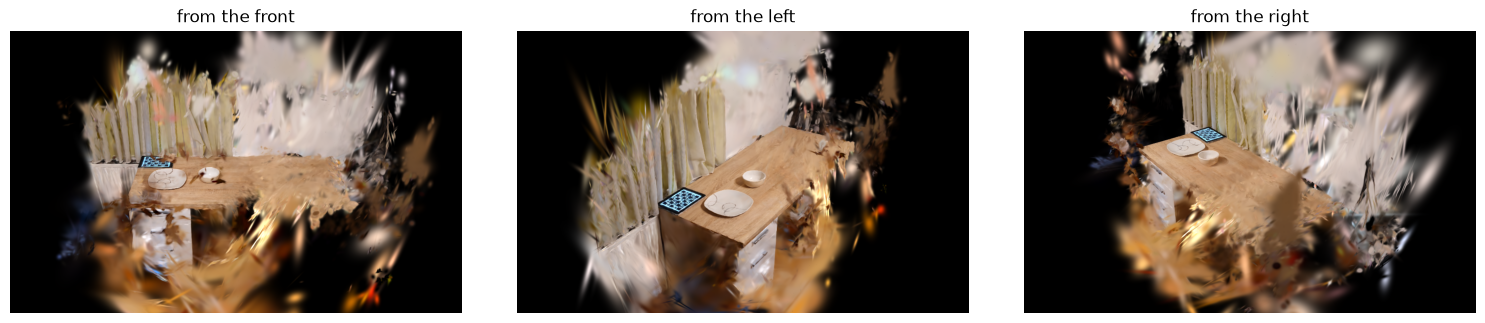

In [6]:
import numpy as np

from hurobo.scan import CropBox, crop_ply
from hurobo.splat import render_scene_views
from hurobo.utils.plotting import plot_image_row

SCENE_CUT = SPLATS / "table_zoom_02_03_scene_cut.ply"
kept = crop_ply(SCENE, SCENE_CUT, [CropBox(-0.39, 1.66, -0.79, 0.61, -2.71, 1.01)])
print(f"{kept:,} of {count:,} Gaussians inside the box")

TARGET = np.array([0.64, -0.1, -0.05])
EYES = {
    "from the front": np.array([0.64, -2.7, 1.5]),
    "from the left": np.array([-1.4, -1.5, 1.3]),
    "from the right": np.array([2.6, -1.6, 1.3]),
}
views = render_scene_views(SCENE_CUT, list(EYES.values()), TARGET)
plot_image_row(dict(zip(EYES, views, strict=True)), height_in=3.2)

### A sweep for the README
The same view moving along an arc in front of the table (the scan only covers that side), saved as `assets/scene_orbit.gif`.

In [7]:
from hurobo.splat import arc_eyes
from hurobo.utils.video import save_gif

sweep = arc_eyes(TARGET, radius=2.3, height=1.4, azimuth_range_deg=(-150, -30), num=14)
gif = save_gif(
    render_scene_views(SCENE_CUT, sweep, TARGET, width=480, height=300), ROOT / "assets/scene_orbit.gif"
)
print(f"{gif.relative_to(ROOT)}: {gif.stat().st_size / 1e6:.1f} MB")

assets/scene_orbit.gif: 2.2 MB
